# Практическое занятие № 10 — оценка классификатора и цена ошибок
**Дисциплина:** Технологии искусственного интеллекта — 1 (ТюмГУ)  
**Время:** 90 минут | **Среда:** Python, scikit-learn, Google Colab  
**Кейс:** бинарная классификация поздней доставки.  
**Результат:** матрица ошибок, метрики, стоимость C(t)=200·FP+2000·FN, выбор порога по validation и **однократная** итоговая проверка на test.  

**Оговорка:** 200 ₽ и 2000 ₽ — условные учебные потери, их нельзя выдавать за установленные экономические эффекты бизнеса.

**Преемственность:** CSV и split_ids взяты из lb9. courier_load отсутствует в данных и исключён; is_weekend сохранён из работ 8–9. Признаки, C=1 и правила подготовки зафиксированы до просмотра test. При повторном техническом запуске решения не изменяются по test; независимой считается первая финальная оценка.

## Шаг 1. Схема данных и воспроизводимая модель (0–15 мин)
Данные разделяем точно по той же процедуре, что и на занятии 9, либо используем `split_ids_06.csv`. Подбор модели и порога по test запрещён.

In [1]:
# Общая подготовка: одинаковая для практик 7 и 8
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PATH = Path('orders_dirty.csv')
if not PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv в файлы Colab или измените PATH.')

from IPython.display import display
import hashlib
source_hash = hashlib.sha256(PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(PATH, encoding='utf-8-sig')
expected = {'order_id','created_at','distance_km','zone','queue_size',
            'weather','promised_minutes','actual_minutes','late'}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f'Отсутствуют необходимые поля: {sorted(missing_cols)}'
print('Сырой набор:', df_raw.shape, '; полные дубликаты:', int(df_raw.duplicated().sum()))

# Удаление полных повторов: не обучаем статистику и не используем test.
df = df_raw.drop_duplicates().copy()
df['late'] = pd.to_numeric(df['late'], errors='coerce')
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
valid_rule = actual.notna() & promised.notna() & df['late'].isin([0, 1])
conflict = valid_rule & (df['late'] != ((actual - promised) > 15).astype(int))
print('Конфликтных меток (проверяемых):', int(conflict.sum()))
df = df.loc[~conflict & df['late'].isin([0, 1])].copy()
df['late'] = df['late'].astype(int)
# Неполные / конфликтные сведения об идентификаторе требуют отдельного решения.
assert df['order_id'].notna().all(), 'Обнаружены пустые ID заказов.'
assert not df['order_id'].duplicated().any(), 'Есть повторные ID: требуется анализ причины, не случайное удаление.'
print('Рабочая копия:', df.shape)

split_path = Path('split_ids_06.csv')  # Необязательный экспорт из практики № 6
if split_path.exists():
    splits = pd.read_csv(split_path, dtype={'order_id': str})
    assert {'order_id', 'split'} <= set(splits.columns)
    assert set(splits['split']) <= {'train', 'val', 'test'}
    assert splits['order_id'].is_unique
    x = df.assign(order_id=df['order_id'].astype(str)).merge(
        splits[['order_id', 'split']], on='order_id', how='left', validate='one_to_one')
    assert x['split'].notna().all(), 'В split_ids_06.csv перечислены не все рабочие заказы.'
    assert set(splits['order_id']) == set(x['order_id'])
    train = x.loc[x['split'] == 'train'].drop(columns='split').copy()
    val   = x.loc[x['split'] == 'val'].drop(columns='split').copy()
    test  = x.loc[x['split'] == 'test'].drop(columns='split').copy()
else:
    # Воссоздание схемы практики № 6, если файл с IDs не был сохранён.
    train_dev, test = train_test_split(df, test_size=.20, stratify=df['late'], random_state=42)
    train, val = train_test_split(train_dev, test_size=.25,
                                 stratify=train_dev['late'], random_state=42)
    split_export = pd.concat([
       train[['order_id']].assign(split='train'),
       val[['order_id']].assign(split='val'),
       test[['order_id']].assign(split='test')], ignore_index=True)
    split_export.to_csv('split_ids_06.csv', index=False)

sets = [set(a['order_id']) for a in (train, val, test)]
assert len(sets[0]&sets[1]) == len(sets[0]&sets[2]) == len(sets[1]&sets[2]) == 0
assert sets[0]|sets[1]|sets[2] == set(df['order_id'])
assert len(train)+len(val)+len(test) == len(df)
print('train / val / test:', len(train), len(val), len(test))

Сырой набор: (600, 10) ; полные дубликаты: 1
Конфликтных меток (проверяемых): 1
Рабочая копия: (598, 10)
train / val / test: 358 120 120


In [2]:
# В Colab функция экспортируется в обычный модуль для безопасного joblib.dump.
# При перезапуске блокнота модуль восстанавливается автоматически.
from pathlib import Path
Path('tyumgu_feature_rules.py').write_text("# Правила преобразования признаков для занятий 7–8\nimport numpy as np\nimport pandas as pd\nNUM_BASE = ['distance_km', 'queue_size',  'promised_minutes']\nCAT = ['zone', 'weather']\nNUM = NUM_BASE + ['hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend']\nINPUT = NUM_BASE + CAT + ['created_at']\n\ndef make_features(X):\n    f = X.loc[:, INPUT].copy()\n    for name in NUM_BASE:\n        f[name] = pd.to_numeric(f[name], errors='coerce')\n    for name in NUM_BASE:\n        f.loc[f[name] < 0, name] = np.nan\n    f.loc[f['promised_minutes'] == 0, 'promised_minutes'] = np.nan\n    for name in CAT:\n        s = f[name].astype('string').str.strip()\n        s = s.mask(s.str.lower().isin(['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))\n        f[name] = s.astype(object).where(s.notna(), np.nan)\n    time = pd.to_datetime(f['created_at'], errors='coerce')\n    hour = time.dt.hour.astype(float)\n    f['is_weekend'] = (time.dt.dayofweek >= 5).astype(float).where(time.notna(), np.nan)\n    f['hour_sin'] = np.sin(2*np.pi*hour/24)\n    f['hour_cos'] = np.cos(2*np.pi*hour/24)\n    f['planned_speed_kmh'] = 60*f['distance_km']/f['promised_minutes']\n    f['planned_speed_kmh'] = f['planned_speed_kmh'].replace([np.inf, -np.inf], np.nan)\n    return f.drop(columns='created_at')\n", encoding='utf-8')
import importlib
import tyumgu_feature_rules
importlib.reload(tyumgu_feature_rules)
from tyumgu_feature_rules import NUM_BASE, NUM, CAT, INPUT, make_features
F_train, F_val = [make_features(part) for part in (train, val)]
assert set(F_train.columns) == set(NUM + CAT)
assert all(col not in F_train.columns for col in ('late','actual_minutes','order_id'))
print('Матрица до кодирования:', F_train.shape)
print('Числовые столбцы:', NUM, '; категориальные:', CAT)

Матрица до кодирования: (358, 9)
Числовые столбцы: ['distance_km', 'queue_size', 'promised_minutes', 'hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend'] ; категориальные: ['zone', 'weather']


In [3]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

numeric_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='median', add_indicator=True,
                           keep_empty_features=True)),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='неизвестно')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, NUM),
    ('cat', cat_pipe, CAT)
], remainder='drop', verbose_feature_names_out=True)

def build_pipeline(classifier):
    return Pipeline([
        ('derive', FunctionTransformer(make_features, validate=False)),
        ('prep', clone(preprocess)),
        ('clf', classifier)
    ])

Xtrain = train[INPUT].copy(); Xval = val[INPUT].copy(); Xtest = test[INPUT].copy()
ytrain = train['late'].astype(int).copy()
yval = val['late'].astype(int).copy()
ytest = test['late'].astype(int).copy()
assert ytrain.nunique() == 2, 'Для обучения необходимы 0 и 1 в train.'
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtrain.columns)
assert set(train['order_id']).isdisjoint(val['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(val['order_id']).isdisjoint(test['order_id'])
print('Обучение:', Xtrain.shape, '| validation:', Xval.shape,
      '| отложенный test:', Xtest.shape)
print('Доли класса late=1 (train / validation):',
      [round(v.mean(), 3) for v in (ytrain,yval)])


Обучение: (358, 6) | validation: (120, 6) | отложенный test: (120, 6)
Доли класса late=1 (train / validation): [np.float64(0.469), np.float64(0.467)]


## Шаг 2. Обучение только на train и вероятности на validation (15–30 мин)
Для сопоставимости фиксируем `C=1`, тот же набор признаков и `random_state=42`.

In [4]:
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,
                             f1_score, balanced_accuracy_score, roc_auc_score,
                             average_precision_score,log_loss,brier_score_loss,
                             PrecisionRecallDisplay, RocCurveDisplay)
import matplotlib.pyplot as plt

model=build_pipeline(LogisticRegression(C=1.0,max_iter=3000,random_state=42))
model.fit(Xtrain,ytrain)
assert list(model.named_steps['clf'].classes_)==[0,1]
val_prob=model.predict_proba(Xval)[:,1]
base=build_pipeline(DummyClassifier(strategy='prior'))
base.fit(Xtrain,ytrain)
base_prob=base.predict_proba(Xval)[:,1]
assert ((val_prob>=0)&(val_prob<=1)).all()
print('validation объектов:',len(val_prob),'положительный класс:',int(yval.sum()))


reference = pd.read_csv('09_val_predictions_reference.csv').set_index('order_id').loc[val.order_id]
np.testing.assert_array_equal(reference.late.to_numpy(), yval.to_numpy())
np.testing.assert_allclose(reference.probability.to_numpy(), val_prob, atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(reference.dummy_probability.to_numpy(), base_prob, atol=1e-12, rtol=1e-12)
num = model.named_steps['prep'].named_transformers_['num']
np.testing.assert_allclose(num.named_steps['fill'].statistics_, F_train[NUM].median())
np.testing.assert_allclose(num.named_steps['scale'].mean_, num.named_steps['fill'].transform(F_train[NUM]).mean(axis=0))
assert model.named_steps['clf'].n_iter_.max() < 3000
print('Вероятности совпали с работой 9; статистики взяты только из train.')
pd.DataFrame({'order_id': val.order_id, 'late': yval, 'probability': val_prob,
              'dummy_probability': base_prob}).to_csv('10_validation_predictions.csv', index=False)

# Проверка категорий и одинаковой обработки обеих моделей только по train.
for fitted in (model, base):
    cat = fitted.named_steps['prep'].named_transformers_['cat']
    train_categories = cat.named_steps['fill'].transform(F_train[CAT])
    for j, learned in enumerate(cat.named_steps['onehot'].categories_):
        np.testing.assert_array_equal(learned, np.unique(train_categories[:, j]))
    assert {'order_id', 'late', 'actual_minutes'}.isdisjoint(INPUT)
np.testing.assert_allclose(model[:-1].transform(Xval), base[:-1].transform(Xval))
print('Категории One-Hot проверены по train; обработка обеих моделей совпадает.')


validation объектов: 120 положительный класс: 56
Вероятности совпали с работой 9; статистики взяты только из train.
Категории One-Hot проверены по train; обработка обеих моделей совпадает.


## Шаг 3. Матрица ошибок и стандартные метрики (30–45 мин)
Порядок классов фиксирован: `labels=[0,1]`; строки — факт, столбцы — прогноз. Положительный класс — задержка.

**Почему Accuracy недостаточно.** Если задерживается только 10% заказов, постоянный прогноз «вовремя» даёт Accuracy=90%, но Recall задержек равен 0. В нашем validation Dummy имеет Accuracy=0,5333, однако не находит ни одной задержки (Recall=F1=0). Поэтому сравниваем также Precision, Recall, F1, Balanced Accuracy и Log Loss; стоимость ошибок оцениваем отдельно.


,модель,порог,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,BalancedAccuracy,LogLoss,Brier,Стоимость_руб
0,Dummy: prior,0.5,64,0,56,0,0.533,0.000,0.000,0.000,0.50,0.691,0.249,112000
1,LogReg,0.5,46,18,19,37,0.692,0.673,0.661,0.667,0.69,0.582,0.198,41600


Log Loss: 0.5818
Brier score: 0.1985


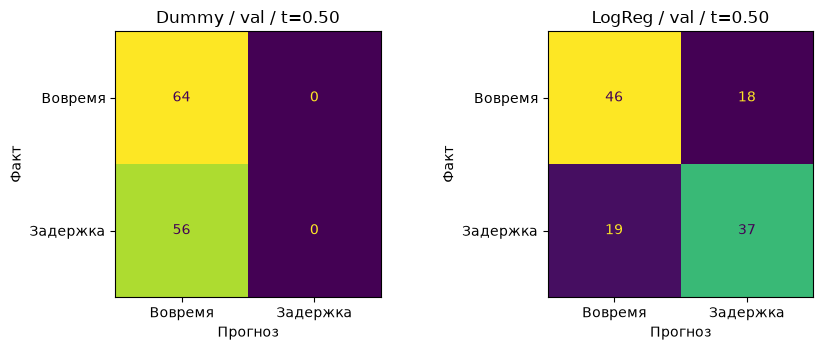

In [5]:
def score_at_threshold(y, probs, threshold, name='LogReg'):
    pred=(np.asarray(probs)>=threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'модель':name,'порог':float(threshold),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'Accuracy':accuracy_score(y,pred),
            'Precision':precision_score(y,pred,zero_division=0),
            'Recall':recall_score(y,pred,zero_division=0),
            'F1':f1_score(y,pred,zero_division=0),
            'BalancedAccuracy':balanced_accuracy_score(y,pred),
            'LogLoss':log_loss(y,probs,labels=[0,1]),
            'Brier':brier_score_loss(y,probs),
            'Стоимость_руб':200*fp+2000*fn}

check=pd.DataFrame([
    score_at_threshold(yval,base_prob,.5,'Dummy: prior'),
    score_at_threshold(yval,val_prob,.5,'LogReg')])
display(check.round(3))
assert (check['TN']+check['FP']+check['FN']+check['TP']==len(yval)).all()
print('Log Loss:',round(log_loss(yval,val_prob,labels=[0,1]),4))
print('Brier score:',round(brier_score_loss(yval,val_prob),4))

check.to_csv('10_validation_models.csv', index=False)
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, probabilities, title in zip(axes, [base_prob, val_prob], ['Dummy / val / t=0.50', 'LogReg / val / t=0.50']):
    ConfusionMatrixDisplay(confusion_matrix(yval, (probabilities >= .5).astype(int), labels=[0,1]),
                           display_labels=['Вовремя', 'Задержка']).plot(ax=ax, colorbar=False)
    ax.set_title(title); ax.set_xlabel('Прогноз'); ax.set_ylabel('Факт')
plt.tight_layout(); plt.savefig('10_confusion_validation.png', dpi=160); plt.show()

## Шаг 4. Три фиксированных порога и стоимость ошибок (45–60 мин)
Считайте C(t)=200·FP(t)+2000·FN(t); сравните `t=0.30`, `0.50`, `0.70`. Изменение порога не переобучает модель.

**Интерпретация трёх порогов.** При t=0,30 получены FP=40 и FN=8, при t=0,50 — FP=18 и FN=19, при t=0,70 — FP=3 и FN=38. Следовательно, среди этих вариантов порог 0,30 снижает число пропущенных задержек ценой роста ложных тревог. Учебная стоимость соответственно равна 24 000, 41 600 и 76 600 рублей. Например, вручную: 200×40 + 2000×8 = 24 000; ниже результат проверяется программно.


,модель,порог,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,BalancedAccuracy,LogLoss,Brier,Стоимость_руб
0,LogReg,0.3,24,40,8,48,0.600,0.545,0.857,0.667,0.616,0.582,0.198,24000
1,LogReg,0.5,46,18,19,37,0.692,0.673,0.661,0.667,0.690,0.582,0.198,41600
2,LogReg,0.7,61,3,38,18,0.658,0.857,0.321,0.468,0.637,0.582,0.198,76600


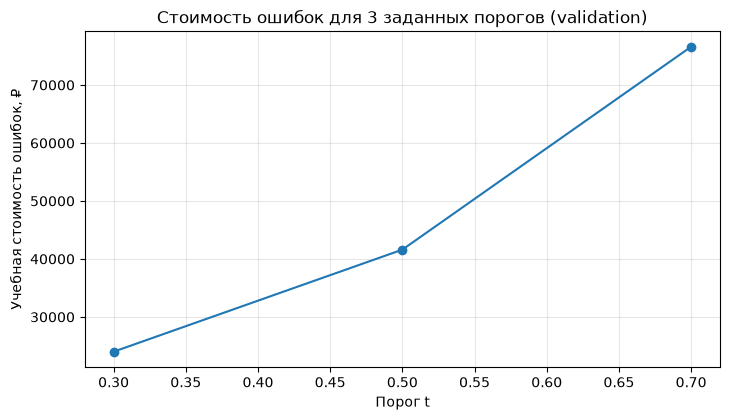

Вручную при t=0.30: 200 × 40 + 2000 × 8 = 24000 учебных рублей.


In [6]:
fixed=pd.DataFrame([score_at_threshold(yval,val_prob,t)
                    for t in [0.30,0.50,0.70]])
display(fixed.round(3))
fixed.to_csv('10_validation_fixed_thresholds.csv',index=False)
fig, ax = plt.subplots(figsize=(7.4,4.3))
ax.plot(fixed['порог'],fixed['Стоимость_руб'],'o-')
ax.set(xlabel='Порог t',ylabel='Учебная стоимость ошибок, ₽',
       title='Стоимость ошибок для 3 заданных порогов (validation)')
ax.grid(alpha=.3); plt.tight_layout(); plt.savefig('10_fixed_cost.png', dpi=160); plt.show()

row = fixed.loc[np.isclose(fixed['порог'], .30)].iloc[0]
manual_cost = 200*int(row.FP) + 2000*int(row.FN)
assert manual_cost == row['Стоимость_руб']
print(f'Вручную при t=0.30: 200 × {int(row.FP)} + 2000 × {int(row.FN)} = {manual_cost} учебных рублей.')

## Шаг 5. Подбор порога ТОЛЬКО на validation (60–75 мин)
Сетка порогов зафиксирована заранее: `0.05…0.95` с шагом `0.05` плюс теоретический порог для калиброванных вероятностей `200/(200+2000)≈0.0909`. При совпадении затрат выбираем больший Recall, затем порог, ближайший к 0.5. Никаких изменений после проверки test.

Полное правило при равенстве: минимальная стоимость → больший Recall → меньшая дистанция до 0,5 → меньший порог. Последний критерий также реализован в сортировке кода.


Теоретический порог при калиброванных вероятностях: 0.0909
Выбранный на validation порог: 0.15


,порог,FP,FN,Precision,Recall,F1,Стоимость_руб
0,0.050,63,0,0.471,1.000,0.640,12600
1,0.091,63,0,0.471,1.000,0.640,12600
2,0.100,63,0,0.471,1.000,0.640,12600
3,0.150,61,0,0.479,1.000,0.647,12200
4,0.200,55,2,0.495,0.964,0.655,15000
5,0.250,48,4,0.520,0.929,0.667,17600
6,0.300,40,8,0.545,0.857,0.667,24000
7,0.350,31,10,0.597,0.821,0.692,26200
8,0.400,26,13,0.623,0.768,0.688,31200
9,0.450,21,15,0.661,0.732,0.695,34200


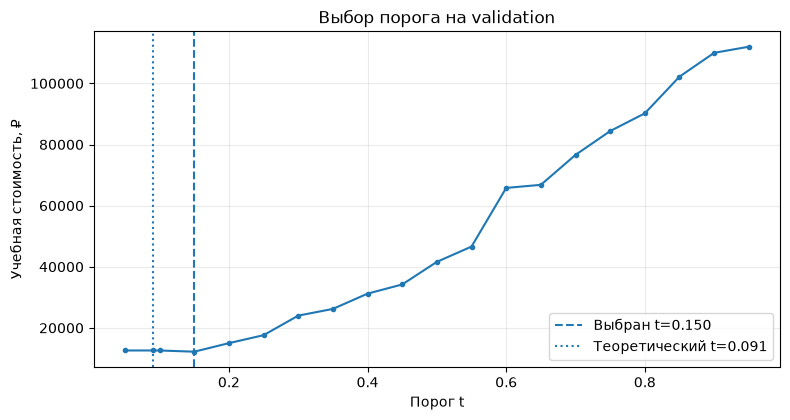

In [7]:
from sklearn.metrics import confusion_matrix
C_FP, C_FN = 200, 2000
bayes_t = C_FP/(C_FP+C_FN)
thresholds=sorted(set([round(t,2) for t in np.arange(.05,1.,.05)] + [bayes_t]))
tuning=pd.DataFrame([score_at_threshold(yval,val_prob,t) for t in thresholds])
tuning['distance_to_half']=(tuning['порог']-.5).abs()
chosen=tuning.sort_values(['Стоимость_руб','Recall','distance_to_half','порог'],
                         ascending=[True,False,True,True]).iloc[0]
selected_t=float(chosen['порог'])
print('Теоретический порог при калиброванных вероятностях:',round(bayes_t,4))
print('Выбранный на validation порог:',round(selected_t,4))
display(tuning[['порог','FP','FN','Precision','Recall','F1','Стоимость_руб']].round(3))
tuning.to_csv('10_validation_threshold_grid.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.3))
ax.plot(tuning['порог'],tuning['Стоимость_руб'],marker='.')
ax.axvline(selected_t,ls='--',label=f'Выбран t={selected_t:.3f}')
ax.axvline(bayes_t,ls=':',label=f'Теоретический t={bayes_t:.3f}')
ax.set(xlabel='Порог t',ylabel='Учебная стоимость, ₽',
       title='Выбор порога на validation')
ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.savefig('10_threshold_cost.png', dpi=160);plt.show()

# Решение сохраняется ДО единственного predict_proba(Xtest).
import joblib
import json
frozen_model_hash = joblib.hash(model)
decision = {'selected_threshold': selected_t, 'C_FP': C_FP, 'C_FN': C_FN,
    'bayes_threshold': bayes_t, 'grid': thresholds,
    'tie_rule': 'cost asc, recall desc, abs(t-0.5) asc, t asc',
    'inputs': list(INPUT), 'features': model.named_steps['prep'].get_feature_names_out().tolist(),
    'C': 1.0, 'max_iter': 3000, 'random_state': 42,
    'model_hash': frozen_model_hash, 'source_sha256': source_hash,
    'test_used_for_selection': False}
Path('10_frozen_decision.json').write_text(json.dumps(decision, ensure_ascii=False, indent=2), encoding='utf-8')
joblib.dump(model, '10_final_model.joblib')
np.testing.assert_allclose(joblib.load('10_final_model.joblib').predict_proba(Xval)[:,1], val_prob)
assert frozen_model_hash == joblib.hash(model)

## Шаг 6. ROC/PR: устойчивость ранжирования (75–80 мин)
AUC и AP оценивают ранжирование, а не стоимость конкретного решения. Если в validation только один класс, эти метрики не определены.

ROC AUC = 0.7547
Average Precision = 0.7403


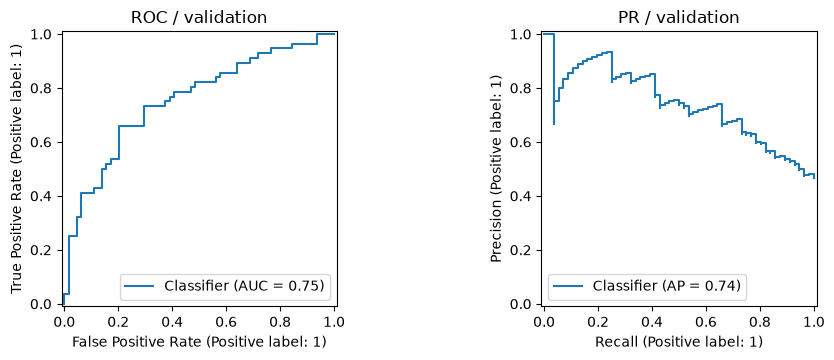

146

In [8]:
if yval.nunique()==2:
    print('ROC AUC =',round(roc_auc_score(yval,val_prob),4))
    print('Average Precision =',round(average_precision_score(yval,val_prob),4))
    fig,axes=plt.subplots(1,2,figsize=(10,3.7))
    RocCurveDisplay.from_predictions(yval,val_prob,ax=axes[0]);axes[0].set_title('ROC / validation')
    PrecisionRecallDisplay.from_predictions(yval,val_prob,ax=axes[1]);axes[1].set_title('PR / validation')
    plt.tight_layout();plt.savefig('10_roc_pr.png', dpi=160);plt.show()
else:
    print('ROC AUC и AP пропущены: validation содержит один класс')

# Та же проверка применимости нужна и при сохранении метрик.
import json
ranking = {'ROC_AUC': float(roc_auc_score(yval, val_prob)) if yval.nunique() == 2 else None,
           'AveragePrecision': float(average_precision_score(yval, val_prob)) if yval.nunique() == 2 else None,
           'positive_fraction_val': float(yval.mean()),
           'applicable': bool(yval.nunique() == 2)}
Path('10_ranking_metrics.json').write_text(json.dumps(ranking, indent=2), encoding='utf-8')


## Шаг 7. Зафиксировать решение и ОДИН РАЗ проверить test (80–88 мин)
`selected_t` уже выбран; здесь **запрещено** менять список признаков, C, способ обработки данных или t на основе результатов test. Если результат разочаровал — документируйте ограничение и план нового эксперимента, но не подгоняйте итог.

In [9]:
assert selected_t == json.loads(Path('10_frozen_decision.json').read_text(encoding='utf-8'))['selected_threshold']
assert frozen_model_hash == joblib.hash(model)
# Единственное обращение к итоговому тесту в блокноте.
test_prob=model.predict_proba(Xtest)[:,1]
test_rows=pd.DataFrame([
    score_at_threshold(ytest,test_prob,.5,'LogReg / фикс. 0.5'),
    score_at_threshold(ytest,test_prob,selected_t,'LogReg / выбор val')
])
display(test_rows.round(4))
test_rows.to_csv('10_final_test_once.csv',index=False)
assert (test_rows['TN']+test_rows['FP']+test_rows['FN']+test_rows['TP']==len(ytest)).all()

import joblib
joblib.dump(model,'10_final_model.joblib')
print('Зафиксированный порог =',selected_t)
print('Сохранена модель. Для её повторной загрузки понадобится tyumgu_feature_rules.py.')

pd.DataFrame({'order_id': test.order_id, 'late': ytest, 'probability': test_prob,
    'prediction_05': (test_prob >= .5).astype(int),
    'prediction_selected': (test_prob >= selected_t).astype(int)}).to_csv('10_test_predictions_once.csv', index=False)
assert len(test_prob) == len(test) and np.isfinite(test_prob).all()
assert frozen_model_hash == joblib.hash(model)
assert hashlib.sha256(PATH.read_bytes()).hexdigest() == source_hash
summary = {'train_n': len(train), 'val_n': len(val), 'test_n': len(test),
    'train_positive': int(ytrain.sum()), 'val_positive': int(yval.sum()), 'test_positive': int(ytest.sum()),
    'selected_t': selected_t, 'selected_val_cost': int(chosen['Стоимость_руб']),
    'manual_cost_at_030': manual_cost, 'model_unchanged': True,
    'test_probability_calls_in_run': 1, 'threshold_changed_after_test': False}
Path('10_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

,модель,порог,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,BalancedAccuracy,LogLoss,Brier,Стоимость_руб
0,LogReg / фикс. 0.5,0.50,43,21,20,36,0.6583,0.6316,0.6429,0.6372,0.6574,0.5979,0.2058,44200
1,LogReg / выбор val,0.15,6,58,1,55,0.5083,0.4867,0.9821,0.6509,0.5379,0.5979,0.2058,13600


Зафиксированный порог = 0.15
Сохранена модель. Для её повторной загрузки понадобится tyumgu_feature_rules.py.


312

## Шаг 8. Выводы и сдача (88–90 мин)
1. Для каждого из 3 порогов приведите TN/FP/FN/TP, Accuracy/Precision/Recall/F1 и стоимость.  
2. Объясните, почему минимальная цена может достигаться при невысокой Accuracy.  
3. Сравните найденный порог с 200/2200; почему они могут отличаться?  
4. Приведите ограничения: синтетические данные, размер выборок, калибровка вероятностей, гипотетические потери.  
5. В отчёте явно зафиксируйте, что test использован однократно после выбора порога.

**Сдать:** `10_student.ipynb`, отчёт №10 (DOCX/PDF), `10_validation_threshold_grid.csv`, `10_final_test_once.csv`.

### Формулы и ответы

Положительный класс — задержка. TN: вовремя и нет тревоги; FP: вовремя, но тревога; FN: задержка без предупреждения; TP: задержка обнаружена. В матрице строки — факт, столбцы — прогноз, порядок [0,1]. Accuracy=(TP+TN)/N; Precision=TP/(TP+FP); Recall=TP/(TP+FN); F1=2PR/(P+R); BalancedAccuracy=(TPR+TNR)/2. При нулевом знаменателе precision/recall/F1 принимаются равными 0.

При снижении t число тревог растёт, FN не увеличивается, FP не уменьшается. Поэтому recall не падает; Precision часто снижается, но на конечной выборке не обязана меняться монотонно. Низкая Accuracy может сопровождаться низкой ценой, если дорогие FN заменяются более дешёвыми FP. По одной Accuracy нельзя определить экономическую выгоду.

При калиброванной p стоимость тревоги равна (1−p)C_FP, а отсутствия тревоги — pC_FN. Тревога выгоднее, когда p≥C_FP/(C_FP+C_FN)=200/2200. Допущения: корректные вероятности, постоянные заданные цены ошибок, нулевая стоимость верных решений и отсутствие иных ограничений. Эмпирический минимум на небольшой validation может отличаться из-за дискретности ошибок и некалиброванных вероятностей. Порог 0,5 не универсален при неравной цене ошибок.

FN может быть опаснее FP, если пропущенное предупреждение лишает сервис времени на вмешательство, приводит к недовольству и компенсациям. FP тоже стоит внимания оператора и может вызвать лишнюю тревогу. Значения 200/2000 — условные учебные веса, не доказанный эффект; реальные стоимости необходимо согласовать с владельцем процесса.

ROC AUC и Average Precision характеризуют ранжирование, а не цену решения и не калибровку. При сильном дисбалансе малая доля FP в ROC может скрывать большое абсолютное число ложных тревог; PR непосредственно показывает precision и recall редкого класса. Базовый уровень precision связан с долей положительных объектов. Здесь AUC/AP вычислены только на validation.

### Протокол и ограничения

Сетка и правило равенств зафиксированы до test: минимальная цена, затем больший Recall, затем близость к 0,5, затем меньший t. Модель, входы, преобразования и порог записаны в 10_frozen_decision.json до predict_proba(Xtest). Test использован одним вызовом для двух заранее определённых порогов (0,5 и selected_t), дальнейшей подгонки не было. Проверка сохранённых чисел не является новым выбором модели; технический перезапуск не создаёт новую независимую оценку.

Для загрузки нужны 10_final_model.joblib, tyumgu_feature_rules.py, совместимые библиотеки из requirements.txt и 10_frozen_decision.json: обычный model.predict использует правило модели, а выбранный бизнес-порог нужно применять к predict_proba отдельно. Test нельзя использовать для корректировок, иначе он превращается в validation и оценка становится оптимистичной.

Ограничения: синтетический характер данных, небольшие части по 120 наблюдений, отсутствие доказанной калибровки и гипотетические цены ошибок. После изменения правил на основании test нужен новый независимый тестовый набор. Исходный CSV и модель после фиксации решения не изменены.

### Числовой итог эксперимента

На validation при t=0,50 LogisticRegression имеет F1=0,6667 и Log Loss=0,5818 против F1=0 и Log Loss=0,6909 у Dummy. По фиксированной сетке выбран t=0,15: FP=61, FN=0, Recall=1, учебная стоимость 12 200 рублей. Аналитический порог 200/2200≈0,0909 даёт FP=63, FN=0 и стоимость 12 600 рублей, поэтому эмпирический минимум отличается от теоретического. ROC AUC=0,7547 и AP=0,7403 характеризуют ранжирование на validation, но не доказывают калибровку вероятностей. После фиксации решения единственная итоговая оценка test дала при t=0,15 FP=58, FN=1, Recall=0,9821 и стоимость 13 600 рублей; для заранее заданного t=0,50 — FP=21, FN=20 и 44 200 рублей. Порог после этого не изменялся; эти условные суммы не доказывают реальную экономию бизнеса.

### Соответствие плану методических указаний

- Проверка структуры и восстановление разделения — шаг 1 ноутбука: очистка, бинарная метка, непересекающиеся ID, одинаковый Pipeline и исключение утечки.
- Обучение и метрики при 0,50 — шаги 2–3: две модели, вероятности validation, матрицы и полная таблица метрик.
- Цена ошибок и оптимизация — шаги 4–5: три порога и график, ручной расчёт, полная сетка и все критерии равенства.
- ROC/PR — шаг 6: кривые, AUC/AP и проверка применимости; интерпретация дисбаланса приведена выше.
- Финальная проверка — шаг 7: фиксация модели и порога до единственного вызова на test, CSV и joblib.
- Выводы и самостоятельная работа — шаг 8: числовой результат, условия аналитического порога, цена FP/FN, ограничения и состав артефактов для загрузки.

